<a href="https://colab.research.google.com/github/marviiiin/Computer-Vision/blob/main/DL4CV_Molmo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install transformers==4.57.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 145.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 38.1 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.8.0
    Uninstalling huggingface_hub-1.8.0:
      Successfully uninstalled huggingface_hub-1.8.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.0.0
    Uninstalling transformers-5.0.0:
      Successfully uninstalled transformers-5.0.0


In [ ]:
!pip install torch pillow einops torchvision accelerate decord2 molmo_utils

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.4/27.4 MB 77.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 70.0 MB/s eta 0:00:00


In [ ]:
import torch
import cv2
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
from transformers import AutoProcessor, AutoModelForImageTextToText

class LVLM:
    def __init__(self):
        # load the processor
        self.processor = AutoProcessor.from_pretrained(
            'allenai/Molmo2-4B',
            trust_remote_code=True,
            torch_dtype='auto',
            device_map='auto'
        )
        # load the model
        self.model = AutoModelForImageTextToText.from_pretrained(
            'allenai/Molmo2-4B',
            trust_remote_code=True,
            torch_dtype='auto',
            device_map='auto'
        )

    def image_prompt(self, image, prompt, max_new_tokens=2048):
        # process the image and text
        messages = [
            {
                "role": "user",
                "content": [
                    dict(type="text", text=prompt),
                    dict(type="image", image=Image.fromarray(image[:,:,::-1]))
                ],
            }
        ]

        inputs = self.processor.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True,
        )

        inputs = {k: v.to(self.model.device) for k, v in inputs.items()}

        # generate output
        with torch.inference_mode():
            generated_ids = self.model.generate(**inputs, max_new_tokens=max_new_tokens)

        # only get generated tokens; decode them to text
        generated_tokens = generated_ids[0, inputs['input_ids'].size(1):]
        generated_text = self.processor.tokenizer.decode(generated_tokens, skip_special_tokens=True)


        # return the generated text
        return generated_text

In [ ]:
molmo = LVLM()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


processor_config.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

processing_molmo2.py: 0.00B [00:00, ?B/s]

video_processing_molmo2.py: 0.00B [00:00, ?B/s]

...

model-00004-of-00004.safetensors:   0%|          | 0.00/4.82G [00:00<?, ?B/s]

model-00003-of-00004.safetensors:   0%|          | 0.00/4.84G [00:00<?, ?B/s]

model-00002-of-00004.safetensors:   0%|          | 0.00/4.84G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/117 [00:00<?, ?B/s]

In [ ]:
import re

COORD_REGEX = re.compile(rf"<(?:points|tracks).*? coords=\"([0-9\t:;, .]+)\"/?>")
FRAME_REGEX = re.compile(rf"(?:^|\t|:|,|;)([0-9\.]+) ([0-9\. ]+)")
POINTS_REGEX = re.compile(r"([0-9]+) ([0-9]{3,4}) ([0-9]{3,4})")

def _points_from_num_str(text, image_w, image_h, extract_ids=False):
    all_points = []
    for points in POINTS_REGEX.finditer(text):
        ix, x, y = points.group(1), points.group(2), points.group(3)
        # our points format assume coordinates are scaled by 1000
        x, y = float(x)/1000*image_w, float(y)/1000*image_h
        if 0 <= x <= image_w and 0 <= y <= image_h:
            yield ix, x, y


def extract_multi_image_points(text, image_w, image_h, extract_ids=False):
    """Extract pointing coordinates as a flattened list of (frame_id, x, y) triplets from model output text."""
    all_points = []
    if isinstance(image_w, (list, tuple)) and isinstance(image_h, (list, tuple)):
        assert len(image_w) == len(image_h)
        diff_res = True
    else:
        diff_res = False
    for coord in COORD_REGEX.finditer(text):
        for point_grp in FRAME_REGEX.finditer(coord.group(1)):
            frame_id = int(point_grp.group(1)) if diff_res else float(point_grp.group(1))
            w, h = (image_w[frame_id-1], image_h[frame_id-1]) if diff_res else (image_w, image_h)
            for idx, x, y in _points_from_num_str(point_grp.group(2), w, h):
                if extract_ids:
                    all_points.append((frame_id, idx, x, y))
                else:
                    all_points.append((frame_id, x, y))
    return all_points

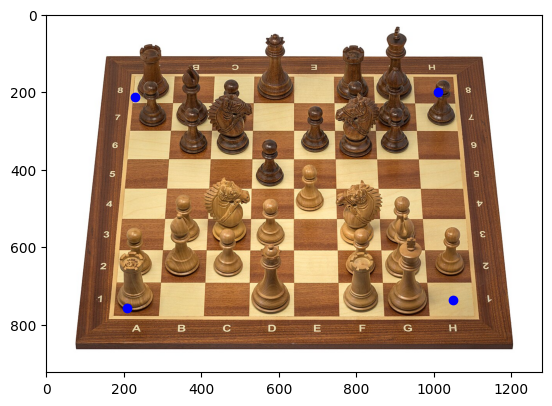

In [ ]:
image = cv2.imread('/content/chess.jpg', cv2.IMREAD_COLOR)

coords = []
result = molmo.image_prompt(image, 'Point to the center of the square A1 of the chess board in this image.')
pointA1 = extract_multi_image_points(result, image.shape[1], image.shape[0])[0]
_,x,y = pointA1
coords.append((int(x+0.5),int(y+0.5)))

result = molmo.image_prompt(image, 'Point to the center of the square A8 of the chess board in this image.')
pointA8 = extract_multi_image_points(result, image.shape[1], image.shape[0])[0]
_,x,y = pointA8
coords.append((int(x+0.5),int(y+0.5)))

result = molmo.image_prompt(image, 'Point to the center of the square H1 of the chess board in this image.')
pointH1 = extract_multi_image_points(result, image.shape[1], image.shape[0])[0]
_,x,y = pointH1
coords.append((int(x+0.5),int(y+0.5)))

result = molmo.image_prompt(image, 'Point to the center of the square H8 of the chess board in this image.')
pointH8 = extract_multi_image_points(result, image.shape[1], image.shape[0])[0]
_,x,y = pointH8
coords.append((int(x+0.5),int(y+0.5)))

# visualize results
fig, ax = plt.subplots()
plt.imshow(image[:,:,::-1])
for x, y in coords:
    plt.scatter([x], [y], c='b')
plt.show()

In [ ]:
import numpy as np

_,x,y = pointA1
pointA1 = np.asarray((x,y))
_,x,y = pointA8
pointA8 = np.asarray((x,y))
_,x,y = pointH1
pointH1 = np.asarray((x,y))
_,x,y = pointH8
pointH8 = np.asarray((x,y))

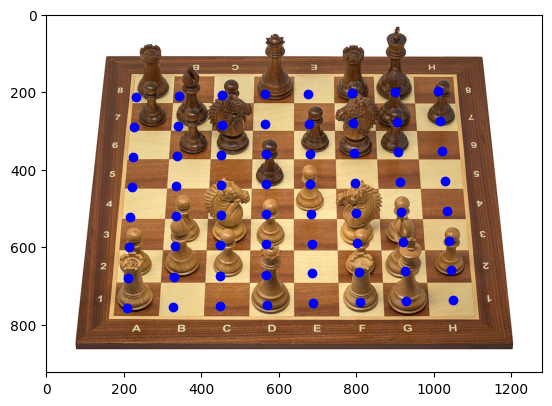

In [ ]:
fig, ax = plt.subplots()
plt.imshow(image[:,:,::-1])

board_points = []
for i in range(8):
  for j in range(8):

    p1 = (j/7)*pointA1 + ((7-j)/7)*pointH1
    p2 = (j/7)*pointA8 + ((7-j)/7)*pointH8
    p = (i/7)*p1 + ((7-i)/7)*p2
    x, y = p
    board_points.append((x,y))
    plt.scatter([x], [y], c='b')

plt.show()

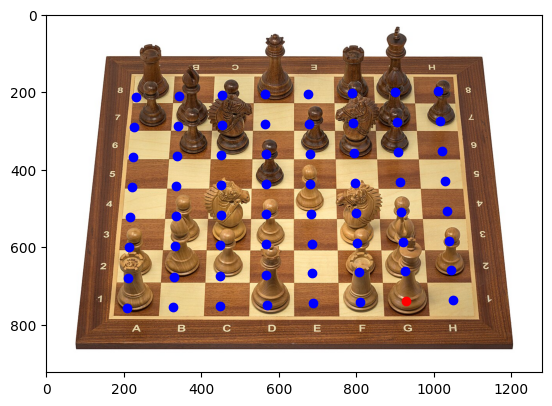

In [ ]:
coords = []
result = molmo.image_prompt(image, 'Point to the base of the white king on the chess board in this image.')
king = extract_multi_image_points(result, image.shape[1], image.shape[0])[0]
_,x,y = king
king = np.asarray((x,y))

dist = np.inf
idx = -1
for i, p in enumerate(board_points):
  dtmp = np.square(np.sum(king-p))
  if dtmp < dist:
    dist = dtmp
    idx = i


fig, ax = plt.subplots()
plt.imshow(image[:,:,::-1])

for i, (x,y) in enumerate(board_points):
    plt.scatter([x], [y], c='b' if i!=idx else 'r')

plt.show()